<a href="https://colab.research.google.com/github/ust-buan-640/buan-640-notebooks/blob/main/notebooks/reg-6-reading-the-line-and-fit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reading the line and measuring the fit

In [ ]:
# Setup: libraries, colors, plotting helpers, and the North Ames data
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Rectangle, FancyBboxPatch
import scipy.stats as stats
import statsmodels.formula.api as smf


PURPLE, GOLD, GRAY, LIGHT, SAND = "#510C76", "#B07A00", "#6E6E6E", "#C9B8D6", "#EFE3C2"
plt.rcParams.update({"font.size": 14, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#444444", "axes.labelcolor": "#222222",
                     "xtick.color": "#444444", "ytick.color": "#444444",
                     "axes.titlesize": 14, "legend.fontsize": 12})
DOLLARS = mtick.FuncFormatter(lambda v, p: "$0" if v == 0 else ("−" if v < 0 else "") + f"${abs(v)/1000:,.0f}K")


def fit(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    b1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
    return y.mean() - b1 * x.mean(), b1


def home_axes(ax, xlim=(700, 2400), ylim=(0, 290000)):
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.yaxis.set_major_formatter(DOLLARS)
    ax.set_xlabel("living area (sq ft)"); ax.set_ylabel("sale price")


na = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/north_ames_2007.csv")
x, y = na.area.values.astype(float), na.price.values.astype(float)
n = len(na)
b0, b1 = fit(x, y)
yhat = b0 + b1 * x
res = y - yhat
s = np.sqrt(np.sum(res ** 2) / (n - 2))
xbar, ybar = x.mean(), y.mean()
ssxx = np.sum((x - xbar) ** 2)
XS = np.linspace(700, 2400, 100)

# a fixed subset of 15 homes for the pictures with error segments
rng = np.random.default_rng(640)
sub = na.iloc[np.sort(rng.choice(n, 15, replace=False))]
xs_, ys_ = sub.area.values.astype(float), sub.price.values.astype(float)
a_s, b_s = fit(xs_, ys_)


def box(ax, cx, cy, w, h, text, ec=PURPLE, fc="white", fs=13):
    ax.add_patch(FancyBboxPatch((cx - w / 2, cy - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=fc, ec=ec, lw=1.6))
    ax.text(cx, cy, text, ha="center", va="center", fontsize=fs)
def arrow(ax, p, q, color=PURPLE):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=color, lw=1.6))

plt.rcParams["figure.dpi"] = 110

We start from the least squares line for all 89 homes.

In [ ]:
from statsmodels.formula.api import ols

homes = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/north_ames_2007.csv")
model = ols("price ~ area", data=homes).fit()
model.params

Intercept    65364.147932
area            63.944944
dtype: float64

## The slope

Read the slope in the units of both variables: dollars of price per square foot of living area.

*Among North Ames homes sold in 2007, each additional square foot of living area is associated with a sale price about \$64 higher, on average.*

It is often easier to say that each additional 100 square feet is associated with about \$6,400 more.

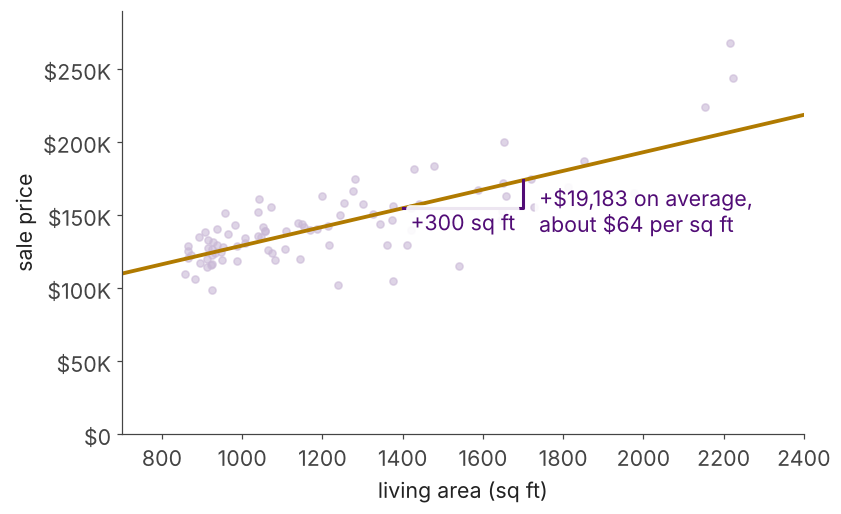

In [ ]:
# ---------------- 5/6. reading the line, fit ----------------
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, color=LIGHT, s=22, zorder=2, alpha=0.6)
ax.plot(XS, b0 + b1 * XS, color=GOLD, lw=2.5)
xa, xb = 1400, 1700
ax.plot([xa, xb, xb], [b0 + b1 * xa, b0 + b1 * xa, b0 + b1 * xb], color=PURPLE, lw=2)
WB = dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.9)
ax.text((xa + xb) / 2, b0 + b1 * xa - 15000, "+300 sq ft", ha="center", color=PURPLE, fontsize=14, bbox=WB)
ax.text(xb + 40, b0 + b1 * xa - 2000, f"+${300 * b1:,.0f} on average,\nabout ${b1:,.0f} per sq ft", color=PURPLE, fontsize=14, va="center", bbox=WB)
home_axes(ax)
plt.show()  # f19_slope.png

## Comparing homes is not renovating one

Recall our discussion of experimental design and causality: these are observational data. Larger homes differ from smaller ones in many ways at once, such as age, lot, and quality. The slope describes the association across homes. It does not say what an addition would do to a given home.

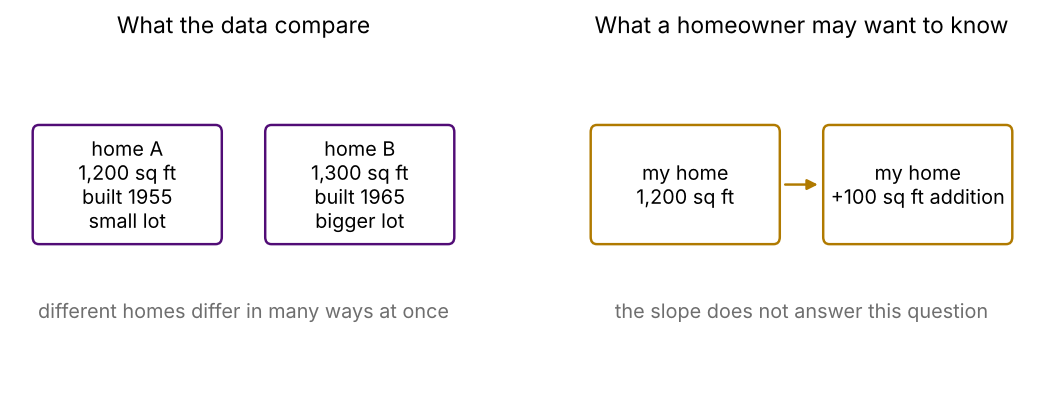

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2));
for ax in axs: ax.set_xlim(0, 6); ax.set_ylim(0, 4); ax.axis("off")
box(axs[0], 1.5, 2.4, 2.4, 1.3, "home A\n1,200 sq ft\nbuilt 1955\nsmall lot")
box(axs[0], 4.5, 2.4, 2.4, 1.3, "home B\n1,300 sq ft\nbuilt 1965\nbigger lot")
axs[0].text(3, 0.9, "different homes differ in many ways at once", ha="center", fontsize=13, color=GRAY)
axs[0].set_title("What the data compare", fontsize=15)
box(axs[1], 1.5, 2.4, 2.4, 1.3, "my home\n1,200 sq ft", ec=GOLD)
box(axs[1], 4.5, 2.4, 2.4, 1.3, "my home\n+100 sq ft addition", ec=GOLD)
arrow(axs[1], (2.75, 2.4), (3.25, 2.4), GOLD)
axs[1].text(3, 0.9, "the slope does not answer this question", ha="center", fontsize=13, color=GRAY)
axs[1].set_title("What a homeowner may want to know", fontsize=15)
plt.show()  # f20_compare_vs_change.png

## The intercept

The intercept is the value of the line at $x = 0$. No home has 0 square feet, so here $b_0$ only positions the line; do not read it as the value of an empty lot. An intercept can be interpreted only when $x = 0$ is within or near the range of the data.

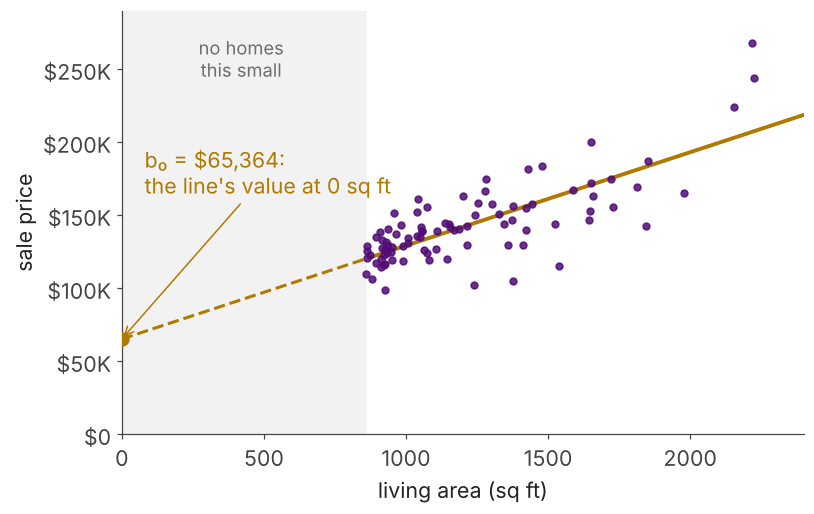

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
X0 = np.linspace(0, 2400, 100)
ax.axvspan(0, x.min(), color="#F2F2F2")
ax.plot(X0, b0 + b1 * X0, color=GOLD, lw=2, ls="--")
ax.plot(XS[XS >= x.min()], b0 + b1 * XS[XS >= x.min()], color=GOLD, lw=2.5)
ax.scatter(x, y, color=PURPLE, s=20, alpha=0.85, zorder=3)
ax.scatter([0], [b0], color=GOLD, s=70, zorder=4)
ax.annotate(f"b₀ = ${b0:,.0f}:\nthe line's value at 0 sq ft", xy=(0, b0), xytext=(80, 165000),
            arrowprops=dict(arrowstyle="->", color=GOLD), color=GOLD)
ax.text(420, 245000, "no homes\nthis small", ha="center", color=GRAY, fontsize=12)
ax.set_xlim(0, 2400); ax.set_ylim(0, 290000); ax.yaxis.set_major_formatter(DOLLARS)
ax.set_xlabel("living area (sq ft)"); ax.set_ylabel("sale price")
plt.show()  # f21_intercept.png

## Predicting, and extrapolating

For a 1,500 sq ft home, $\hat{y} = 65{,}364 + 63.94(1{,}500) \approx \$161{,}000$. For a 3,800 sq ft home the line gives about \$308,000, but no home in the data is larger than 2,223 square feet, and we have no idea whether the straight line still holds out there.

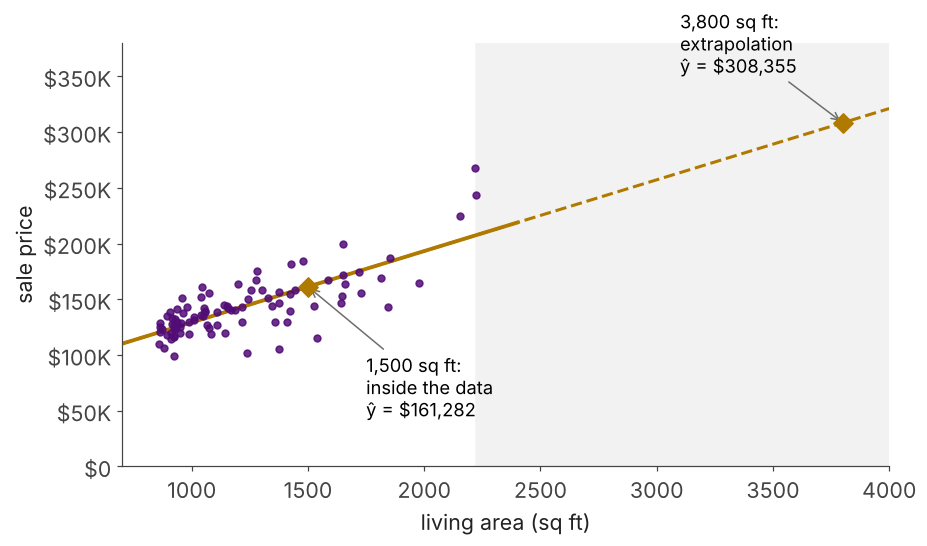

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
XE = np.linspace(700, 4000, 100)
ax.axvspan(x.max(), 4000, color="#F2F2F2")
ax.plot(XE, b0 + b1 * XE, color=GOLD, lw=2, ls="--"); ax.plot(XS, b0 + b1 * XS, color=GOLD, lw=2.5)
ax.scatter(x, y, color=PURPLE, s=20, alpha=0.85, zorder=3)
for xp, lab in [(1500, "1,500 sq ft:\ninside the data"), (3800, "3,800 sq ft:\nextrapolation")]:
    yp = b0 + b1 * xp
    ax.scatter([xp], [yp], color=GOLD, s=80, zorder=4, marker="D")
    ax.annotate(f"{lab}\nŷ = ${yp:,.0f}", xy=(xp, yp), xytext=(xp - 700 if xp > 3000 else xp + 250, yp + 45000 if xp > 3000 else 45000),
                arrowprops=dict(arrowstyle="->", color=GRAY), fontsize=12)
ax.set_xlim(700, 4000); ax.set_ylim(0, 380000); ax.yaxis.set_major_formatter(DOLLARS)
ax.set_xlabel("living area (sq ft)"); ax.set_ylabel("sale price")
plt.show()  # f22_prediction.png

In [ ]:
model.predict(pd.DataFrame({"area": [1500, 3800]}))

0    161281.564070
1    308354.935481
dtype: float64

## Splitting each home's price

Without $x$, our best guess for every home is the average price $\bar{y}$. For each home, the distance from $\bar{y}$ splits into the part the line explains and the part left over:

$$(y_i - \bar{y}) = (\hat{y}_i - \bar{y}) + (y_i - \hat{y}_i)$$

The part left over, $y_i - \hat{y}_i$, is the **residual**: the observed prediction error for that home.

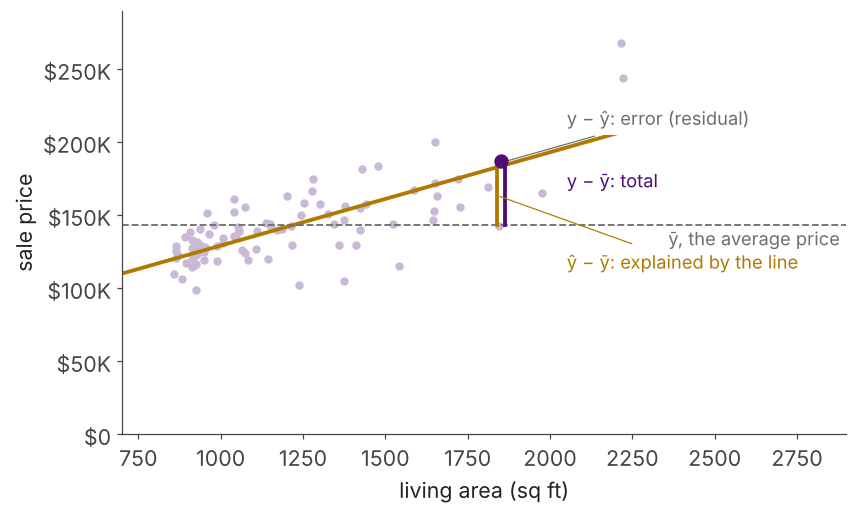

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(x, y, color=LIGHT, s=20, zorder=2)
ax.plot(XS, b0 + b1 * XS, color=GOLD, lw=2.5); ax.axhline(ybar, color=GRAY, ls="--", lw=1.2)
j = int(np.argmax(np.where((x > 1700) & (x < 2000), y - yhat, -1e9)))
xj, yj, yhj = x[j], y[j], yhat[j]
ax.scatter([xj], [yj], color=PURPLE, s=70, zorder=4)
ax.plot([xj + 12] * 2, [ybar, yj], color=PURPLE, lw=2.5)
ax.plot([xj - 12] * 2, [ybar, yhj], color=GOLD, lw=2.5)
ax.plot([xj - 12] * 2, [yhj, yj], color=GRAY, lw=2.5)
ax.annotate("y − ŷ: error (residual)", xy=(xj - 12, (yj + yhj) / 2), xytext=(xj + 200, yj + 25000), color=GRAY, bbox=dict(fc="white", ec="none"),
            fontsize=12, arrowprops=dict(arrowstyle="-", color=GRAY, lw=0.8))
ax.text(xj + 200, (yj + ybar) / 2 + 4000, "y − ȳ: total", color=PURPLE, fontsize=12, bbox=dict(fc="white", ec="none"))
ax.annotate("ŷ − ȳ: explained by the line", xy=(xj - 12, (yhj + ybar) / 2), xytext=(xj + 200, ybar - 30000), color=GOLD, bbox=dict(fc="white", ec="none"),
            fontsize=12, arrowprops=dict(arrowstyle="-", color=GOLD, lw=0.8))
ax.text(2880, ybar - 14000, "ȳ, the average price", color=GRAY, fontsize=12, ha="right")
home_axes(ax, xlim=(700, 2900))
plt.show()  # f23_decomposition.png

## Sums of squares

Square each part and add over all homes, and the pieces still add up:

| | Formula | North Ames |
|---|---|---:|
| Total, SST | $\sum (y - \bar{y})^2$ | 68.55 billion |
| Explained by the line, SSR | $\sum (\hat{y} - \bar{y})^2$ | 40.54 billion |
| Error, SSE | $\sum (y - \hat{y})^2$ | 28.00 billion |

$$SST = SSR + SSE$$

This is the same structure as the ANOVA table, where total = between + within. SSE is the quantity least squares made as small as possible.

SSE is computed from residuals, but it is called the *error* sum of squares because the residuals stand in for the unobservable errors $\varepsilon$; that is also the name of the within-group row in ANOVA. Software labels differ, so watch out:

- Excel's ANOVA table calls the rows Regression and Residual.
- In statsmodels, `model.ssr` is the sum of squared **residuals**, which is our SSE, and `model.ess` is the explained sum of squares, our SSR.

In [ ]:
sst = model.centered_tss
ssr = model.ess        # explained by the line: our SSR
sse = model.ssr        # sum of squared residuals: our SSE
print(f"SST = {sst:,.0f}\nSSR = {ssr:,.0f}\nSSE = {sse:,.0f}")

SST = 68,547,065,618
SSR = 40,543,330,867
SSE = 28,003,734,751


## R², the coefficient of determination

$$R^2 = \frac{SSR}{SST} = 1 - \frac{SSE}{SST} = \frac{40.54}{68.55} = 0.59$$

*Living area explains about 59% of the variation in sale prices among these 89 homes.*

R² does not mean that the line predicts 59% of homes correctly, and it does not mean that 59% of the price is caused by size.

In [ ]:
model.rsquared

np.float64(0.5914670526240888)

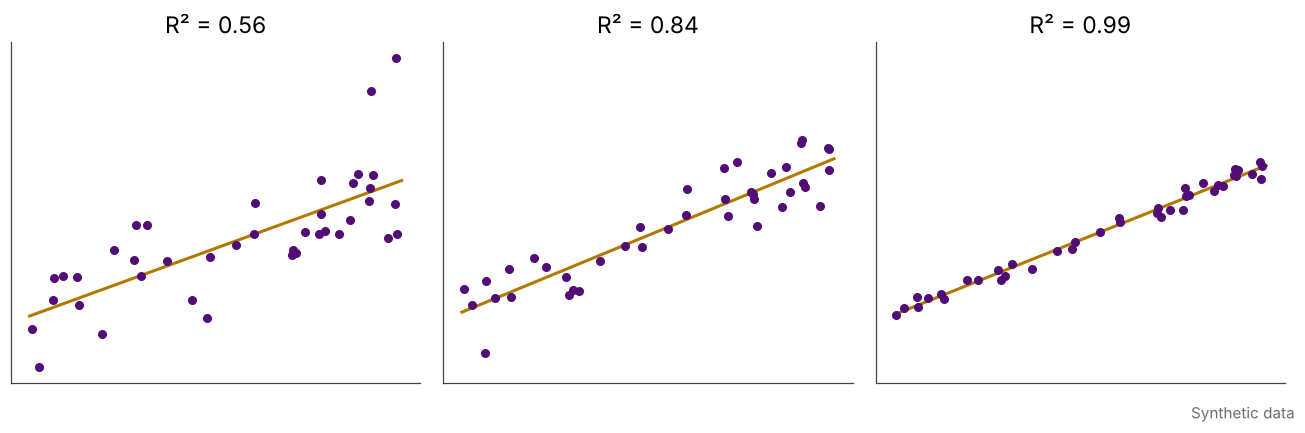

In [ ]:
rng9 = np.random.default_rng(9)
xx = rng9.uniform(0, 10, 40)
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, sd in zip(axs, [6, 2.5, 0.8]):
    yy = 5 + 2 * xx + rng9.normal(0, sd, 40)
    aa, bb = fit(xx, yy)
    ax.scatter(xx, yy, color=PURPLE, s=24, zorder=3); ax.plot([0, 10], [aa, aa + 10 * bb], color=GOLD, lw=2)
    ax.set_title(f"R² = {stats.pearsonr(xx, yy)[0] ** 2:.2f}", fontsize=15); ax.set_xticks([]); ax.set_yticks([])
fig.text(0.99, -0.03, "Synthetic data", ha="right", fontsize=10, color=GRAY)
fig.tight_layout(); plt.show()  # f24_r2_compare.png

Same line, different scatter. The closer the points lie to the line, the larger R². It is always between 0 and 1.

## The typical prediction error, $s_e$

$$s_e = \sqrt{\frac{SSE}{n-2}} = \sqrt{MSE} = \$17{,}941$$

$s_e$ estimates $\sigma_\varepsilon$, the standard deviation of the error $\varepsilon$. We divide by $n - 2$ because two numbers, $b_0$ and $b_1$, were estimated from the data. In plain words, a typical home sells about \$18,000 above or below the line.

Our textbook and Excel write this simply as $s$ (Excel's label is Standard Error, in the Regression Statistics table). We add the subscript $e$ to keep it apart from $s_y$, the ordinary standard deviation of the prices.

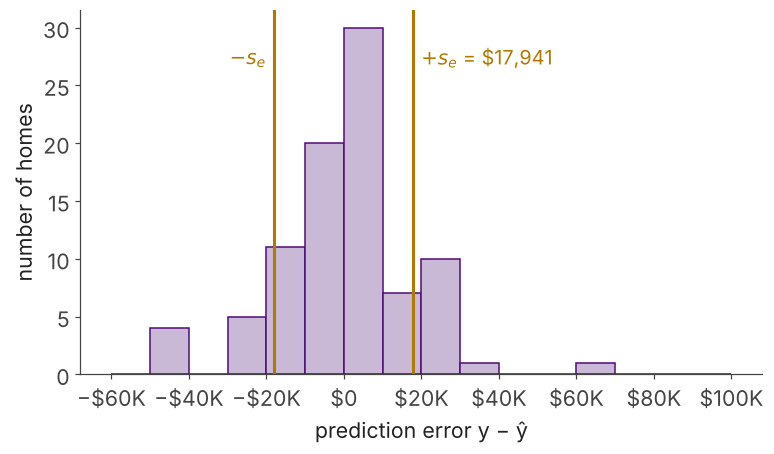

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.3))
ax.hist(res, bins=np.arange(-60000, 100001, 10000), color=LIGHT, edgecolor=PURPLE)
for v in (-s, s):
    ax.axvline(v, color=GOLD, lw=2)
ax.text(s + 2000, ax.get_ylim()[1] * 0.85, f"$+s_e$ = \\${s:,.0f}", color=GOLD, fontsize=13)
ax.text(-s - 2000, ax.get_ylim()[1] * 0.85, "$-s_e$", color=GOLD, fontsize=13, ha="right")
ax.xaxis.set_major_formatter(DOLLARS); ax.set_xlabel("prediction error y − ŷ"); ax.set_ylabel("number of homes")
plt.show()  # f25_residual_hist.png

In [ ]:
np.sqrt(model.mse_resid)

np.float64(17941.070442725304)

## Two different spreads

Since $y = \beta_0 + \beta_1 x + \varepsilon$, homes of a given size vary around the line only through $\varepsilon$. So $\sigma_\varepsilon$ is also the standard deviation of $Y$ given $X = x$: the spread of prices among homes of the same size. The equal-variance assumption is what lets one number describe that spread at every size.

It is not the spread of all prices. That one, $s_y$, also includes the differences that come from homes being different sizes.

| | Population | Sample | North Ames |
|---|---|---|---|
| Spread of all prices | $\sigma_Y$ | $s_y$ | \$27,910 |
| Spread around the line: of $Y$ given $X = x$, and of $\varepsilon$ | $\sigma_\varepsilon$ | $s_e$ | \$17,941 |

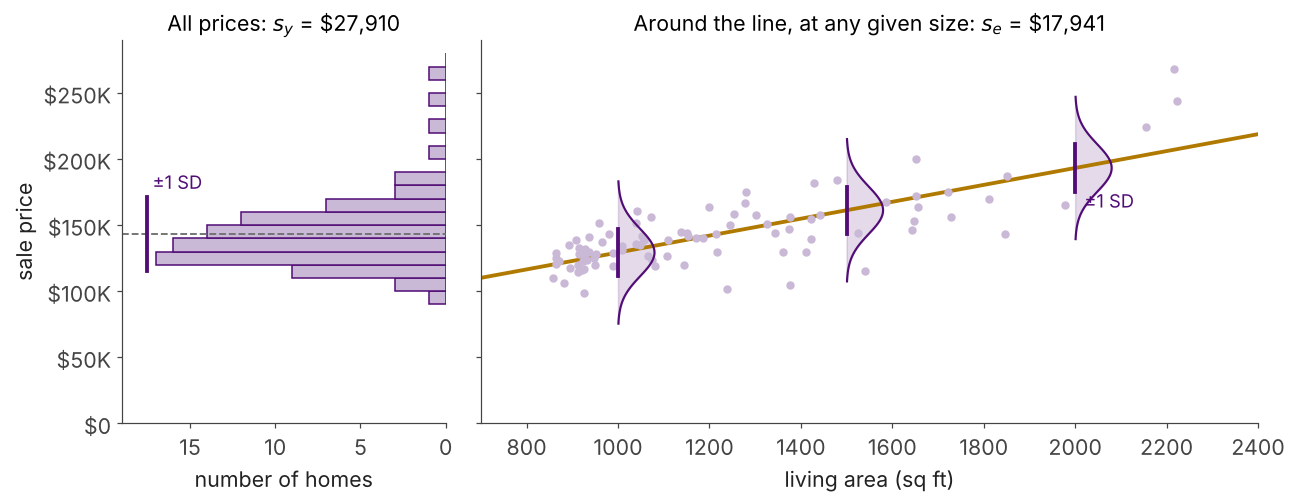

In [ ]:
# ---------------- 6. spread of prices overall vs around the line ----------------
s_y = y.std(ddof=1)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True, gridspec_kw={"width_ratios": [1, 2.4]})
axs[0].hist(y, bins=np.arange(90000, 280001, 10000), orientation="horizontal", color=LIGHT, edgecolor=PURPLE)
axs[0].axhline(ybar, color=GRAY, ls="--", lw=1.2)
axs[0].plot([17.5, 17.5], [ybar - s_y, ybar + s_y], color=PURPLE, lw=2.5)
axs[0].set_xlim(19, 0); axs[0].set_xlabel("number of homes")
axs[0].set_title(f"All prices: $s_y$ = \\${s_y:,.0f}")
axs[0].yaxis.set_major_formatter(DOLLARS); axs[0].set_ylim(0, 290000); axs[0].set_ylabel("sale price")
axs[1].plot(XS, b0 + b1 * XS, color=GOLD, lw=2.5)
axs[1].scatter(x, y, color=LIGHT, s=20, zorder=2)
for xc in [1000, 1500, 2000]:
    mu = b0 + b1 * xc
    yy = np.linspace(mu - 3 * s, mu + 3 * s, 100)
    dd = stats.norm.pdf(yy, mu, s) * s * 200
    axs[1].fill_betweenx(yy, xc, xc + dd, color=PURPLE, alpha=0.15)
    axs[1].plot(xc + dd, yy, color=PURPLE, lw=1.4)
    axs[1].plot([xc, xc], [mu - s, mu + s], color=PURPLE, lw=2.5)
axs[0].text(17.2, ybar + s_y + 6000, "±1 SD", color=PURPLE, fontsize=12)
axs[1].text(2020, b0 + b1 * 2000 - s - 12000, "±1 SD", color=PURPLE, fontsize=12, ha="left")
home_axes(axs[1]); axs[1].set_ylabel("")
axs[1].set_title(f"Around the line, at any given size: $s_e$ = \\${s:,.0f}")
fig.tight_layout(); plt.show()  # f36_two_spreads.png

In [ ]:
s_y = homes["price"].std()
s_e = np.sqrt(model.mse_resid)
print(f"s_y = {s_y:,.0f}   s_e = {s_e:,.0f}")

s_y = 27,910   s_e = 17,941


Knowing a home's size shrinks the typical miss from about \$28,000 to about \$18,000. The two spreads are tied to R²: $1 - s_e^2 / s_y^2 = 0.587$, which is the adjusted R² in the regression output.